# 02 · Retention-driver analysis (GA4): ASSOCIATIONS ONLY
**Outcome:** any event in [t0+24h, t0+31d), for new non-bot users with the full window observed.
**Features:** first 24 hours only (leakage control, asserted in SQL).
**Read with:** `docs/correlation_vs_causation.md`.

In [1]:
import sys, json, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, display, Markdown
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.precision", 4)
FIG = ROOT / "reports" / "figures"

In [2]:
from src.analysis import retention_drivers as rd
r = rd.run()
print(r['n'], 'users; outcome rate', round(r['outcome_rate'],4))

168471 users; outcome rate 0.0814


## Logistic regression: odds ratios with 95% CIs
Numeric features are log1p-transformed and standardized, so each OR is per SD. Reference levels are the largest groups.

,feature,odds_ratio,or_ci_low,or_ci_high,p_value
5,used_search,0.4144,0.3811,0.4506,3.7112e-94
2,log_page_views,1.6241,1.5730,1.6769,4.3212e-194
3,log_engagement_min,1.2993,1.2619,1.3378,3.2813e-69
4,added_to_cart,0.8554,0.7922,0.9236,6.5840e-05
1,log_product_views,0.8928,0.8717,0.9144,1.3894e-20
15,country_grp_Germany,0.9016,0.7819,1.0396,1.5407e-01
6,channel_(obfuscated),0.9222,0.8754,0.9716,2.3321e-03
13,country_grp_China,1.0510,0.9164,1.2054,4.7674e-01
18,country_grp_Spain,0.9614,0.8389,1.1018,5.7111e-01
16,country_grp_India,1.0375,0.9731,1.1063,2.6042e-01


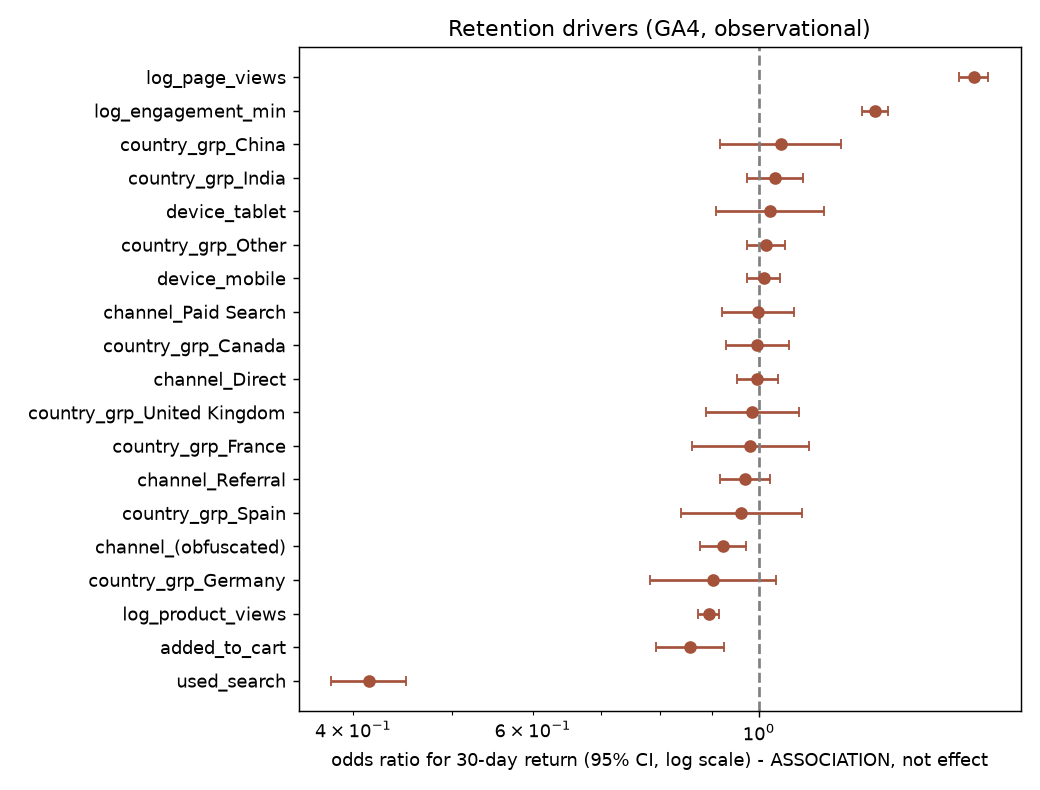

In [3]:
display(r['logit'][['feature','odds_ratio','or_ci_low','or_ci_high','p_value']]); display(Image(FIG / 'retention_driver_or.png'))

## Collinearity

In [4]:
r['vif']

,feature,vif
0,log_product_views,2.9166
1,log_page_views,4.6178
2,log_engagement_min,4.1939
3,added_to_cart,1.3290
4,used_search,1.1629


## Raw rates vs adjusted ORs: sign flips

In [5]:
pd.DataFrame({k: {'returned_if_1': v['returned_if_1']['rate'], 'returned_if_0': v['returned_if_0']['rate']} for k, v in r['binary_descriptives'].items()}).T

,returned_if_1,returned_if_0
added_to_cart,0.1973,0.0766
used_search,0.1082,0.0800


## Intent confounder check
Purchase-intent proxies (began checkout, purchased in the first 24h) are added to the model.

In [6]:
print('page-view OR unadjusted', round(r['unadjusted_top_or']['odds_ratio'],3), '-> with intent proxies', round(r['intent_adjusted_top_or']['odds_ratio'],3))
r['intent_proxies_or']

page-view OR unadjusted 1.624 -> with intent proxies 1.803


,feature,coef,odds_ratio,or_ci_low,or_ci_high,p_value,abs_log_or
20,began_checkout,-1.4152,0.2429,0.2145,0.2750,2.0595e-110,1.4152
21,purchased_24h,1.0961,2.9925,2.5750,3.4776,2.2510e-46,1.0961


## Logistic vs gradient boosting (30% holdout)

In [7]:
{k: v for k, v in r['model_comparison'].items() if k != 'gb_permutation_importance'}

{'holdout_n': 50542,
 'auc_logistic': 0.6909502251029958,
 'auc_gradient_boosting': 0.7156597045646945}

In [8]:
r['model_comparison']['gb_permutation_importance']

,feature,auc_drop_mean,auc_drop_sd
1,log_page_views,1.5265e-01,1.0241e-02
2,log_engagement_min,3.0446e-02,2.2096e-03
4,used_search,4.2498e-03,1.4427e-03
0,log_product_views,3.1827e-03,4.9812e-04
3,added_to_cart,2.3136e-03,4.4507e-04
16,country_grp_Other,4.9160e-04,1.2234e-04
6,channel_Direct,2.9976e-04,1.1544e-04
12,country_grp_China,1.5396e-04,6.4970e-05
15,country_grp_India,1.3207e-04,7.3670e-05
11,country_grp_Canada,1.2569e-04,1.5230e-04


## Follow-up experiment for the strongest positive candidate

In [9]:
r['follow_up_experiment']

{'candidate_behaviour': 'log_page_views',
 'hypothesis': "Adding a 'continue browsing' module (related collections) to landing pages increases first-visit page depth and, through it, 30-day return among new visitors.",
 'randomization_unit': 'user_pseudo_id (new visitors at first_visit), 50/50',
 'primary_metric': 'return within [t0+24h, t0+31d) (same definition as the driver model)',
 'secondary_metrics': ['log_page_views in first 24h (manipulation check)',
  'add-to-cart in first 24h',
  '7-day purchase conversion'],
 'guardrails': ['7-day purchase conversion (non-inferiority, margin 0.1 pp)',
  'page load time',
  'bounce rate (single-event sessions)'],
 'baseline_rate': 0.08143834843979082,
 'alpha': 0.05,
 'power': 0.8,
 'observed_new_users_per_day': 2796.5760869565215,
 'designs': [{'mde_pp_absolute': 0.5,
   'n_per_arm': 48272,
   'enrolment_days_at_observed_traffic': 35,
   'total_duration_days': 66},
  {'mde_pp_absolute': 1.0,
   'n_per_arm': 12387,
   'enrolment_days_at_obser